In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import chi2_contingency
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve
%matplotlib inline

In [2]:
# Load the shipping dataset
ship = pd.read_csv('Train.csv')
ship.head()

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


In [3]:
# Confirm target coding: 1 = NOT delivered on time, 0 = delivered on time
print(ship['Reached.on.Time_Y.N'].value_counts())
print()
print('Late rate:', round(ship['Reached.on.Time_Y.N'].mean() * 100, 2), '%')

Reached.on.Time_Y.N
1    6563
0    4436
Name: count, dtype: int64

Late rate: 59.67 %


This confirms the target variable's coding: 1 indicates the shipment did *not* arrive on time (late), and 0 indicates it arrived on time. This is the reverse of what the column name `Reached.on.Time_Y.N` suggests, and was verified here before proceeding.

In [4]:
# Dataset structure and quality check
print('Shape:', ship.shape)
print()
print('Data types:')
print(ship.dtypes)
print()
print('Missing values:', ship.isnull().sum().sum())
print('Duplicate rows:', ship.duplicated().sum())

Shape: (10999, 12)

Data types:
ID                      int64
Warehouse_block        object
Mode_of_Shipment       object
Customer_care_calls     int64
Customer_rating         int64
Cost_of_the_Product     int64
Prior_purchases         int64
Product_importance     object
Gender                 object
Discount_offered        int64
Weight_in_gms           int64
Reached.on.Time_Y.N     int64
dtype: object

Missing values: 0
Duplicate rows: 0


In [5]:
# Summary statistics for numeric variables
ship.describe()

,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
count,10999.00000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000
mean,5500.00000,4.054459,2.990545,210.196836,3.567597,13.373216,3634.016729,0.596691
std,3175.28214,1.141490,1.413603,48.063272,1.522860,16.205527,1635.377251,0.490584
min,1.00000,2.000000,1.000000,96.000000,2.000000,1.000000,1001.000000,0.000000
25%,2750.50000,3.000000,2.000000,169.000000,3.000000,4.000000,1839.500000,0.000000
50%,5500.00000,4.000000,3.000000,214.000000,3.000000,7.000000,4149.000000,1.000000
75%,8249.50000,5.000000,4.000000,251.000000,4.000000,10.000000,5050.000000,1.000000
max,10999.00000,7.000000,5.000000,310.000000,10.000000,65.000000,7846.000000,1.000000


In [6]:
# Late delivery rate by each categorical variable
for col in ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']:
    print(f'--- Late rate by {col} ---')
    rates = ship.groupby(col)['Reached.on.Time_Y.N'].agg(['mean', 'size'])
    rates['late_%'] = (rates['mean'] * 100).round(2)
    print(rates[['late_%', 'size']])
    print()

--- Late rate by Warehouse_block ---
                 late_%  size
Warehouse_block              
A                 58.65  1833
B                 60.23  1833
C                 59.68  1833
D                 59.76  1834
F                 59.85  3666

--- Late rate by Mode_of_Shipment ---
                  late_%  size
Mode_of_Shipment              
Flight             60.16  1777
Road               58.81  1760
Ship               59.76  7462

--- Late rate by Product_importance ---
                    late_%  size
Product_importance              
high                 64.98   948
low                  59.28  5297
medium               59.05  4754

--- Late rate by Gender ---
        late_%  size
Gender              
F        59.44  5545
M        59.90  5454



In [7]:
# Chi-square test of independence: Product_importance vs late delivery
contingency = pd.crosstab(ship['Product_importance'], ship['Reached.on.Time_Y.N'])
chi2, p, dof, expected = chi2_contingency(contingency)

print("Observed frequencies:")
print(contingency)
print()

print("Expected frequencies:")
print(pd.DataFrame(expected, index=contingency.index, columns=contingency.columns).round(2))
print()

print('Chi-square statistic:', round(chi2, 4))
print('p-value:', round(p, 6))
print('Degrees of freedom:', dof)

Observed frequencies:
Reached.on.Time_Y.N     0     1
Product_importance             
high                  332   616
low                  2157  3140
medium               1947  2807

Expected frequencies:
Reached.on.Time_Y.N        0        1
Product_importance                   
high                  382.34   565.66
low                  2136.33  3160.67
medium               1917.33  2836.67

Chi-square statistic: 12.2112
p-value: 0.00223
Degrees of freedom: 2


In [8]:
# Effect size (Cramér's V) for the chi-square result
n = contingency.sum().sum()
min_dim = min(contingency.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))
print("Cramér's V:", round(cramers_v, 4))

Cramér's V: 0.0333


The results: **chi-square is 12.2112 (df=2)**, and the **p-value is 0.00223**, well below **α = .05**, so there is sufficient evidence to reject the null hypothesis that late rates are equal across importance levels. However, **Cramér's V is 0.0333**, which means the strength of the association between product importance and late delivery is negligible. This means that product importance alone isn't strong enough to predict lateness. However, with 10,999 records, even small differences can reach statistical significance, so the effect size matters alongside the p-value.

In [9]:
# Build predictor matrix for logistic regression
# Numeric predictors
X = ship[['Discount_offered', 'Weight_in_gms']].copy()

# Convert Product_importance into dummy variables (drop_first avoids redundancy)
importance_dummies = pd.get_dummies(ship['Product_importance'], 
                                     prefix='imp', drop_first=True).astype(int)
X = pd.concat([X, importance_dummies], axis=1)

# Add intercept
X = sm.add_constant(X).astype(float)
y = ship['Reached.on.Time_Y.N']

X.head()

,const,Discount_offered,Weight_in_gms,imp_low,imp_medium
0,1.0,44.0,1233.0,1.0,0.0
1,1.0,59.0,3088.0,1.0,0.0
2,1.0,48.0,3374.0,1.0,0.0
3,1.0,10.0,1177.0,0.0,1.0
4,1.0,46.0,2484.0,0.0,1.0


In [10]:
# Fit binary logistic regression
logit_model = sm.Logit(y, X)
results = logit_model.fit()
print(results.summary())

Optimization terminated successfully.
         Current function value: 0.549936
         Iterations 8
                            Logit Regression Results                           
Dep. Variable:     Reached.on.Time_Y.N   No. Observations:                10999
Model:                           Logit   Df Residuals:                    10994
Method:                            MLE   Df Model:                            4
Date:                 Sat, 12 Sep 2026   Pseudo R-squ.:                  0.1845
Time:                         22:36:47   Log-Likelihood:                -6048.7
converged:                        True   LL-Null:                       -7417.0
Covariance Type:             nonrobust   LLR p-value:                     0.000
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.2732      0.104      2.622      0.009       0.069       0.477
Dis

The regression results allow us to reject the null hypothesis. All four predictors are statistically significant (p < .001).

**Discount_offered (+0.1174)**: A higher discount indicates a greater likelihood of late delivery. For each additional discount unit, the log-odds of lateness increase by 0.1174, raising the odds of lateness by about 12.5%. Since discounts range from 1 to 65, this compounds substantially: a 10-unit increase raises the odds of lateness by a factor of 3.24

**Weight_in_gms (−0.0002)**: Heavier packages are less likely to be late. For each additional gram, the log-odds of lateness decrease by 0.0002. While small per gram, the effect adds up across the full weight range, with each additional kilogram lowering them by about 15.4%

**imp_low (−0.3306)**: Low-importance shipments are less likely to be late than high-importance shipments.

**imp_medium (−0.3222)**: Medium-importance shipments are also less likely to be late than high-importance shipments.

The Pseudo *R-squared is 0.1845*, indicating the model substantially improves on a null model with no predictors and is a reasonable fit for this type of data.

In [11]:
# Convert coefficients to odds ratios for interpretation
odds_ratios = pd.DataFrame({
    'coefficient': results.params,
    'odds_ratio': np.exp(results.params),
    'p_value': results.pvalues
})
print(odds_ratios.round(4))

                  coefficient  odds_ratio  p_value
const                  0.2732      1.3142   0.0087
Discount_offered       0.1174      1.1246   0.0000
Weight_in_gms         -0.0002      0.9998   0.0000
imp_low               -0.3306      0.7185   0.0001
imp_medium            -0.3222      0.7246   0.0001


In [12]:
# Predicted probabilities and classifications at 0.5 threshold
predicted_prob = results.predict(X)
predicted_class = (predicted_prob >= 0.5).astype(int)

print('Accuracy :', round(accuracy_score(y, predicted_class), 4))
print('Precision:', round(precision_score(y, predicted_class), 4))
print('Recall   :', round(recall_score(y, predicted_class), 4))
print('ROC-AUC  :', round(roc_auc_score(y, predicted_prob), 4))
print('Baseline (all late):', round(y.mean(), 4))
print()
print('Confusion matrix:')
print(confusion_matrix(y, predicted_class))

Accuracy : 0.634
Precision: 0.6978
Recall   : 0.6819
ROC-AUC  : 0.7173
Baseline (all late): 0.5967

Confusion matrix:
[[2498 1938]
 [2088 4475]]


The model's accuracy is 63.40%, beating the 59.67% baseline of simply predicting "late" for every shipment by about 3.7 percentage points, which is a modest improvement. Accuracy alone here is not a viable metric, because a useless model already gets nearly 60% right by default.

The ROC-AUC is 0.7173, which is a more informative number. It tells us the probability that the model assigns a higher risk score to a randomly chosen late shipment than to a randomly chosen on-time one. A score of 0.5 means the model performs no better than random, while 0.72 means the model has real discriminatory power. This is the strongest single performance figure.

Precision is 0.6978, meaning when the model flags a shipment as late, it is right about 70% of the time. Recall is 0.6819, meaning the model correctly identifies about 68% of shipments that actually arrived late.

The confusion matrix is:

|  Confusion Matrix  | Predicted on-time | Predicted late |
|--------------------|-------------------|----------------|
| Actually on-time   | 2,498             | 1,938          |
| Actually late      | 2,088             | 4,475          |

This shows that 4,475 late shipments were correctly flagged, 2,088 were missed, and 1,938 on-time shipments were flagged unnecessarily. That last pair represents the operational tradeoff. Every flag carries a cost, be it expediting, a proactive call, or extra handling. Flagging nearly 2,000 orders that would have arrived fine is the price of catching over 4,000 that would not. The data cannot determine whether the cost of a false alarm outweighs the cost of a missed late delivery. 

The 0.5 threshold used for classification is a choice, not a rule. Lowering it would catch more late shipments but increase false alarms; raising it would do the reverse. This is a lever the company can adjust based on its own cost structure.

In [13]:
# Check multicollinearity among predictors (excluding the constant)
X_vif = X.drop(columns='const')
vif = pd.DataFrame({
    'variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
print(vif.round(3))

           variable    VIF
0  Discount_offered  1.606
1     Weight_in_gms  4.025
2           imp_low  2.988
3        imp_medium  2.989


A multicollinearity check was performed using Variance Inflation Factors (VIF). All values fell below 5, with Discount_offered at 1.606, Weight_in_gms at 4.025, imp_low at 2.988, and imp_medium at 2.989. This indicates that multicollinearity is not a concern and the coefficient estimates are stable.

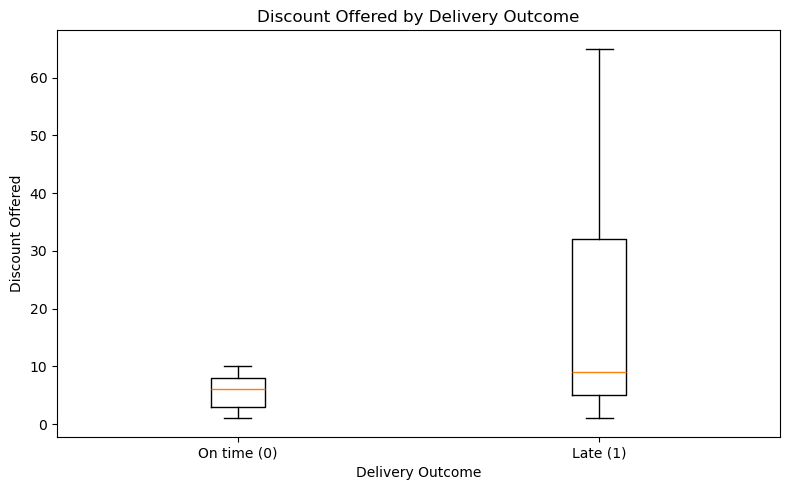

Median discount - on time: 6.0 | late: 9.0
On-time — Q1: 3.0 | Q3: 8.0
Late     — Q1: 5.0 | Q3: 32.0
On-time — min: 1 | max: 10
Late     — min: 1 | max: 65


In [14]:
# Visualization 1: Discount offered by delivery outcome
on_time = ship[ship['Reached.on.Time_Y.N'] == 0]['Discount_offered']
late = ship[ship['Reached.on.Time_Y.N'] == 1]['Discount_offered']

plt.figure(figsize=(8, 5))
plt.boxplot([on_time, late], tick_labels=['On time (0)', 'Late (1)'])
plt.title('Discount Offered by Delivery Outcome')
plt.xlabel('Delivery Outcome')
plt.ylabel('Discount Offered')
plt.tight_layout()
plt.show()

print('Median discount - on time:', on_time.median(), '| late:', late.median())

print('On-time — Q1:', on_time.quantile(0.25), '| Q3:', on_time.quantile(0.75))
print('Late     — Q1:', late.quantile(0.25), '| Q3:', late.quantile(0.75))
print('On-time — min:', on_time.min(), '| max:', on_time.max())
print('Late     — min:', late.min(), '| max:', late.max())

The on-time box ran from a first quartile of 3 to a third quartile of 8, with its whisker extending to the maximum on-time value of 10. The late box ran from a first quartile of 5 to a third quartile of 32, with its whisker extending to the maximum discount value observed in the dataset, 65. Neither group contained statistical outliers and both whiskers reached their group's true maximum, since all values fell within 1.5 times the interquartile range of each box. The bottom halves of the two distributions overlapped almost completely (on time box spanning 3 to 8, late box spanning 5 to 32), while the separation was concentrated entirely in the upper range, where the late group's box and whisker extends four times further at the third quartile than the on-time group's.

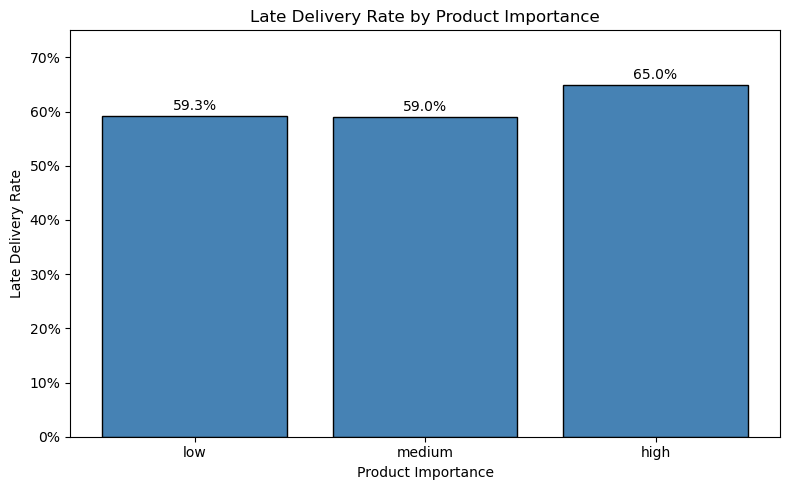

In [15]:
# Visualization 2: Late delivery rate by product importance
order = ['low', 'medium', 'high']
rates = ship.groupby('Product_importance')['Reached.on.Time_Y.N'].mean().reindex(order)

plt.figure(figsize=(8, 5))
plt.bar(order, rates.values, color='steelblue', edgecolor='black')
plt.title('Late Delivery Rate by Product Importance')
plt.xlabel('Product Importance')
plt.ylabel('Late Delivery Rate')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
plt.ylim(0, 0.75)
for i, v in enumerate(rates.values):
    plt.text(i, v + 0.01, f'{v:.1%}', ha='center')
plt.tight_layout()
plt.show()

The late delivery rate was 59.3% for low-importance shipments, 59.0% for medium-importance shipments, and 65.0% for high-importance shipments. This visualizes the chi-square finding directly: high-importance shipments, the ones the company would presumably most want to arrive on time, were in fact the most likely of the three groups to be late. Given that Cramér's V (0.0333) indicates this association is practically negligible in strength, the takeaway is not that importance is a strong predictor on its own, but that this counterintuitive pattern is worth investigating as a process question rather than a statistical one.

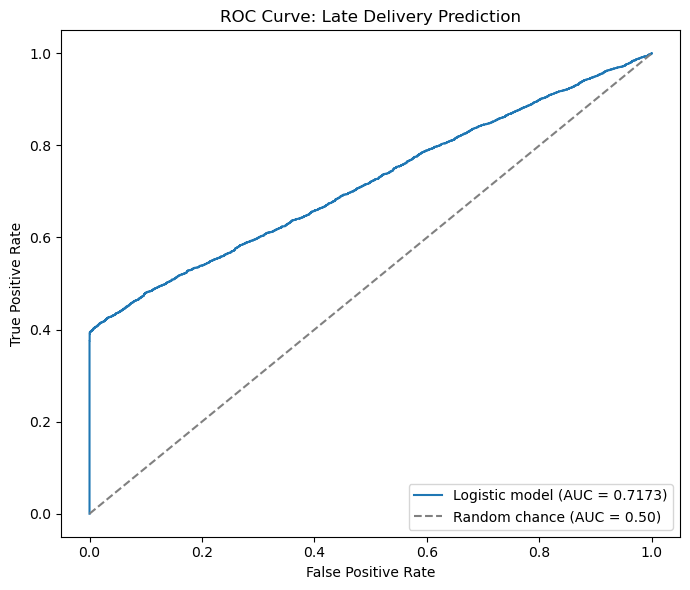

In [16]:
# Visualization 3: ROC curve
probs = results.predict(X)
fpr, tpr, thresholds = roc_curve(y, probs)
auc = roc_auc_score(y, probs)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'Logistic model (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Random chance (AUC = 0.50)')
plt.title('ROC Curve: Late Delivery Prediction')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

The ROC curve plots the model's true positive rate against its false positive rate across all possible classification thresholds. The model's AUC of 0.7173 is well above the 0.5 line representing random chance, indicating meaningful discriminatory power and the model is more than 70% likely to assign a higher risk score to a randomly chosen late shipment than to a randomly chosen on-time one. The curve also makes the threshold tradeoff visible: moving along the curve trades true positives for false positives, which is the same operational tradeoff described above and the same lever the company can adjust based on its own cost structure.